In [ ]:

import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not available")


PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
from torchvision.datasets import OxfordIIITPet

trainval_dataset = OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="segmentation",
    download=True
)

test_dataset = OxfordIIITPet(
    root="./data",
    split="test",
    target_types="segmentation",
    download=True
)

print("Train + Validation:", len(trainval_dataset))
print("Test:", len(test_dataset))
print("Total:", len(trainval_dataset) + len(test_dataset))


Train + Validation: 3680
Test: 3669
Total: 7349


Image size: (394, 500)
Mask size: (394, 500)
Mask values: [1 2 3]


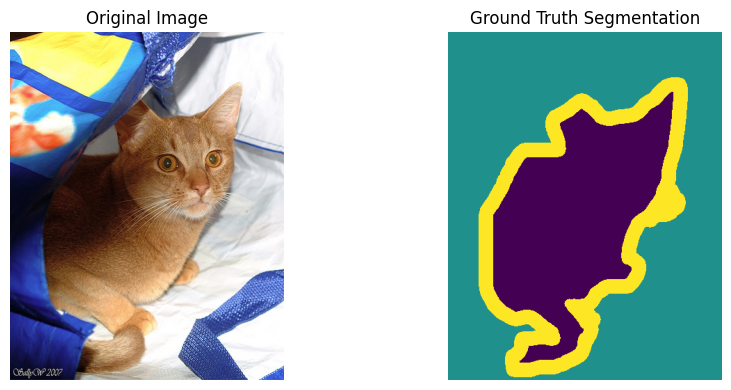

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

image, mask = trainval_dataset[0]

print("Image size:", image.size)
print("Mask size:", mask.size)
print("Mask values:", np.unique(np.array(mask)))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(mask, cmap="viridis", vmin=1, vmax=3)
axes[1].set_title("Ground Truth Segmentation")
axes[1].axis("off")

plt.tight_layout()
plt.show()


Original mask values: [1 2 3]
Binary mask values: [0 1]


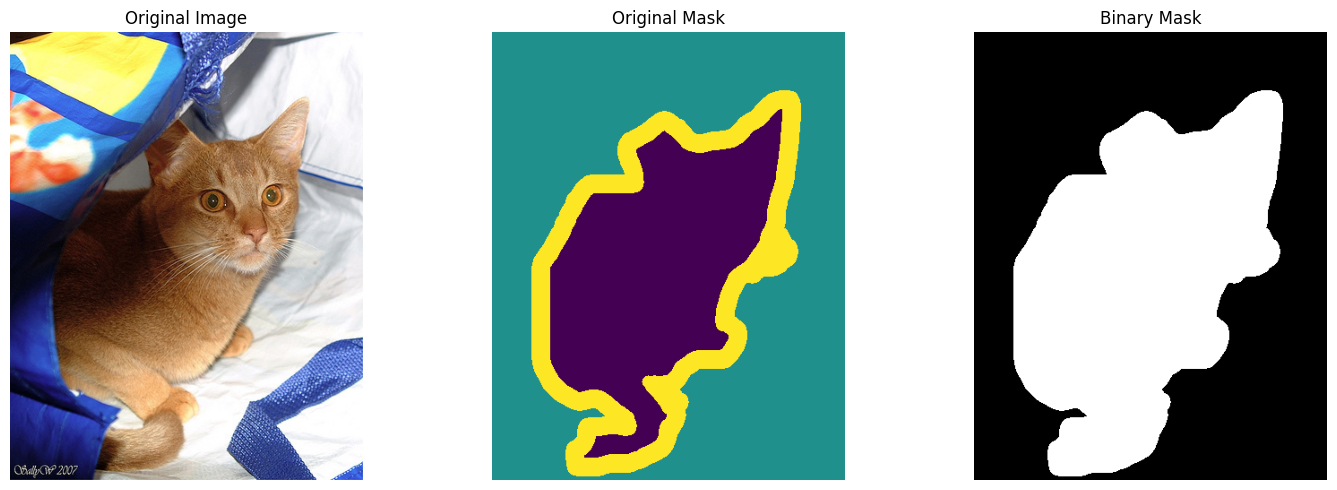

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

image, mask = trainval_dataset[0]

mask_array = np.array(mask)

# 1 = Animal, 0 = Background
binary_mask = (mask_array != 2).astype(np.uint8)

print("Original mask values:", np.unique(mask_array))
print("Binary mask values:", np.unique(binary_mask))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(mask_array, cmap="viridis", vmin=1, vmax=3)
axes[1].set_title("Original Mask")
axes[1].axis("off")

axes[2].imshow(binary_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Binary Mask")
axes[2].axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import torch
import numpy as np

from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

IMAGE_SIZE = (256, 256)

class PetSegmentationDataset(Dataset):

    def __init__(self, subset):
        self.subset = subset

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):

        image, mask = self.subset[idx]

        # Resize image
        image = TF.resize(
            image,
            IMAGE_SIZE,
            interpolation=InterpolationMode.BILINEAR
        )

        # Resize segmentation mask
        mask = TF.resize(
            mask,
            IMAGE_SIZE,
            interpolation=InterpolationMode.NEAREST
        )

        # Convert image to tensor and normalize
        image = TF.to_tensor(image)

        image = TF.normalize(
            image,
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

        # Convert segmentation mask to binary
        mask = np.array(mask)
        mask = (mask != 2).astype(np.float32)

        # Convert mask to tensor
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask


In [ ]:

BATCH_SIZE = 16

train_data = PetSegmentationDataset(train_subset)
val_data = PetSegmentationDataset(val_subset)
test_data = PetSegmentationDataset(test_dataset)

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Training batches: 184
Validation batches: 46
Test batches: 230


In [ ]:

images, masks = next(iter(train_loader))

print("Images shape:", images.shape)
print("Masks shape:", masks.shape)
print("Mask unique values:", torch.unique(masks))
print("Images dtype:", images.dtype)
print("Masks dtype:", masks.dtype)

assert images.shape[1:] == (3, 256, 256)
assert masks.shape[1:] == (1, 256, 256)
assert set(torch.unique(masks).tolist()).issubset({0.0, 1.0})

print("All preprocessing checks passed!")


Images shape: torch.Size([16, 3, 256, 256])
Masks shape: torch.Size([16, 1, 256, 256])
Mask unique values: tensor([0., 1.])
Images dtype: torch.float32
Masks dtype: torch.float32
All preprocessing checks passed!


In [ ]:

import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


In [ ]:

class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(3, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(128, 256)

        # Decoder
        self.up3 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, 2)
        self.dec1 = DoubleConv(64, 32)

        # Output: one channel for binary segmentation
        self.output = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):
        # Encoding
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        # Bottleneck
        b = self.bottleneck(self.pool(e3))

        # Decoding + skip connections
        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.output(d1)


In [ ]:

import torch
import torch.nn as nn

# Binary Cross-Entropy Loss
bce_loss = nn.BCEWithLogitsLoss()

# Dice Loss
def dice_loss(predictions, targets, smooth=1e-6):

    probabilities = torch.sigmoid(predictions)

    probabilities = probabilities.flatten(start_dim=1)
    targets = targets.flatten(start_dim=1)

    intersection = (probabilities * targets).sum(dim=1)

    denominator = (
        probabilities.sum(dim=1) +
        targets.sum(dim=1)
    )

    dice = (
        (2.0 * intersection + smooth) /
        (denominator + smooth)
    )

    return 1.0 - dice.mean()


# Combined Loss
def combined_loss(predictions, targets):

    bce = bce_loss(predictions, targets)
    dice = dice_loss(predictions, targets)

    return bce + dice


print("Loss functions created successfully!")


Loss functions created successfully!


In [ ]:

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = UNet().to(device)

print("Device:", device)

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# Test with a single fake RGB image
dummy_input = torch.randn(1, 3, 256, 256).to(device)

model.eval()

with torch.no_grad():
    output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)

assert output.shape == (1, 1, 256, 256)

print("U-Net architecture test passed!")


Device: cuda
Total parameters: 1,928,417
Trainable parameters: 1,928,417
Input shape: torch.Size([1, 3, 256, 256])
Output shape: torch.Size([1, 1, 256, 256])
U-Net architecture test passed!


In [ ]:

import torch.optim as optim

LEARNING_RATE = 0.001

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

print("Optimizer:", type(optimizer).__name__)
print("Learning rate:", LEARNING_RATE)


Optimizer: AdamW
Learning rate: 0.001


In [ ]:

# Get one training batch
images, masks = next(iter(train_loader))

# Move data to GPU
images = images.to(device)
masks = masks.to(device)

# Enable training mode
model.train()

# Clear old gradients
optimizer.zero_grad()

# Forward pass
predictions = model(images)

# Calculate loss
loss = combined_loss(predictions, masks)

# Backward pass
loss.backward()

# Update model parameters
optimizer.step()

print("Images:", images.shape)
print("Predictions:", predictions.shape)
print("Targets:", masks.shape)
print("Loss:", round(loss.item(), 4))
print("Single training batch passed!")


Images: torch.Size([16, 3, 256, 256])
Predictions: torch.Size([16, 1, 256, 256])
Targets: torch.Size([16, 1, 256, 256])
Loss: 1.3052
Single training batch passed!


In [ ]:

required_objects = [
    "train_loader",
    "val_loader",
    "model",
    "device",
    "optimizer",
    "combined_loss"
]

for name in required_objects:
    status = "OK" if name in globals() else "MISSING"
    print(f"{name}: {status}")


train_loader: OK
val_loader: OK
model: OK
device: OK
optimizer: OK
combined_loss: OK


In [ ]:

from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_data = PetSegmentationDataset(train_subset)
val_data = PetSegmentationDataset(val_subset)

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("DataLoaders created successfully!")


Training batches: 184
Validation batches: 46
DataLoaders created successfully!


In [ ]:

import torch
from torch.utils.data import random_split
from torchvision.datasets import OxfordIIITPet

SEED = 42

# Reload existing dataset
trainval_dataset = OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="segmentation",
    download=True
)

# Restore original train/validation split
total_size = len(trainval_dataset)

train_size = int(0.8 * total_size)
val_size = total_size - train_size

train_subset, val_subset = random_split(
    trainval_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

print("Training images:", len(train_subset))
print("Validation images:", len(val_subset))
print("Dataset split restored!")


100%|██████████| 792M/792M [00:38<00:00, 20.8MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 7.46MB/s]


Training images: 2944
Validation images: 736
Dataset split restored!


In [ ]:

print(
    "PetSegmentationDataset exists:",
    "PetSegmentationDataset" in globals()
)


PetSegmentationDataset exists: True


In [ ]:

from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_data = PetSegmentationDataset(train_subset)
val_data = PetSegmentationDataset(val_subset)

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("DataLoaders restored successfully!")


Training batches: 184
Validation batches: 46
DataLoaders restored successfully!


In [ ]:

# Get one batch
images, masks = next(iter(train_loader))

# Move data to GPU
images = images.to(device)
masks = masks.to(device)

# Training mode
model.train()

# Clear gradients
optimizer.zero_grad()

# Forward pass
predictions = model(images)

# Calculate loss
loss = combined_loss(predictions, masks)

# Backpropagation
loss.backward()

# Update model weights
optimizer.step()

# Display results
print("Images:", images.shape)
print("Predictions:", predictions.shape)
print("Targets:", masks.shape)
print("Loss:", round(loss.item(), 4))

print("Single training batch passed!")


Images: torch.Size([16, 3, 256, 256])
Predictions: torch.Size([16, 1, 256, 256])
Targets: torch.Size([16, 1, 256, 256])
Loss: 1.2916
Single training batch passed!


In [ ]:

from pathlib import Path

SAVE_DIR = Path("/content/PetVision")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

print("Save directory:", SAVE_DIR)
print("Directory exists:", SAVE_DIR.exists())


Save directory: /content/PetVision
Directory exists: True


In [ ]:

required_objects = [
    "model",
    "device",
    "train_loader",
    "val_loader",
    "combined_loss",
    "optimizer",
    "SAVE_DIR",
    "calculate_metrics",
    "train_one_epoch",
    "validate_one_epoch"
]

missing = []

for name in required_objects:
    if name in globals():
        print(f"{name}: OK")
    else:
        print(f"{name}: MISSING")
        missing.append(name)

if not missing:
    print("\nEverything is ready for training!")
else:
    print("\nMissing components:", missing)


model: OK
device: OK
train_loader: OK
val_loader: OK
combined_loss: OK
optimizer: OK
SAVE_DIR: OK
calculate_metrics: MISSING
train_one_epoch: MISSING
validate_one_epoch: MISSING

Missing components: ['calculate_metrics', 'train_one_epoch', 'validate_one_epoch']


In [ ]:

import torch

def calculate_metrics(logits, targets, smooth=1e-6):

    probabilities = torch.sigmoid(logits)
    predictions = (probabilities > 0.5).float()

    predictions = predictions.flatten(start_dim=1)
    targets = targets.flatten(start_dim=1)

    intersection = (predictions * targets).sum(dim=1)

    pred_sum = predictions.sum(dim=1)
    target_sum = targets.sum(dim=1)

    dice = (
        (2 * intersection + smooth) /
        (pred_sum + target_sum + smooth)
    )

    union = pred_sum + target_sum - intersection

    iou = (
        (intersection + smooth) /
        (union + smooth)
    )

    return dice.mean().item(), iou.mean().item()


print("Evaluation metrics ready!")


Evaluation metrics ready!


In [ ]:

def train_one_epoch(model, loader, optimizer, device):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for images, masks in loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = combined_loss(outputs, masks)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


@torch.no_grad()
def validate_one_epoch(model, loader, device):

    model.eval()

    total_loss = 0.0
    total_dice = 0.0
    total_iou = 0.0
    total_samples = 0

    for images, masks in loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)
        loss = combined_loss(outputs, masks)

        dice, iou = calculate_metrics(outputs, masks)

        batch_size = images.size(0)

        total_loss += loss.item() * batch_size
        total_dice += dice * batch_size
        total_iou += iou * batch_size

        total_samples += batch_size

    return (
        total_loss / total_samples,
        total_dice / total_samples,
        total_iou / total_samples
    )


print("Training and validation functions ready!")


Training and validation functions ready!


In [ ]:

required_functions = [
    "calculate_metrics",
    "train_one_epoch",
    "validate_one_epoch"
]

for name in required_functions:
    print(name, ":", "OK" if name in globals() else "MISSING")

assert all(name in globals() for name in required_functions)

print("Ready for full training!")


calculate_metrics : OK
train_one_epoch : OK
validate_one_epoch : OK
Ready for full training!


In [ ]:

import random
import numpy as np
import pandas as pd
import torch
import torch.optim as optim

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Initialize a fresh model
model = UNet().to(device)

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

EPOCHS = 5
best_dice = -1.0
history = []

print("Starting baseline training...", flush=True)

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model, train_loader, optimizer, device
    )

    val_loss, val_dice, val_iou = validate_one_epoch(
        model, val_loader, device
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_dice": val_dice,
        "val_iou": val_iou
    })

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Dice: {val_dice:.4f} | "
        f"IoU: {val_iou:.4f}",
        flush=True
    )

    if val_dice > best_dice:
        best_dice = val_dice

        torch.save(
            model.state_dict(),
            SAVE_DIR / "unet_baseline_best.pth"
        )

        print("Best model saved!", flush=True)

    pd.DataFrame(history).to_csv(
        SAVE_DIR / "baseline_history.csv",
        index=False
    )

print("\nTraining completed!")
print(f"Best validation Dice: {best_dice:.4f}")


Starting baseline training...
Epoch 1/5 | Train Loss: 0.9120 | Val Loss: 1.0694 | Dice: 0.7063 | IoU: 0.5696
Best model saved!
Epoch 2/5 | Train Loss: 0.7369 | Val Loss: 0.6824 | Dice: 0.7873 | IoU: 0.6631
Best model saved!
Epoch 3/5 | Train Loss: 0.6648 | Val Loss: 0.5908 | Dice: 0.8141 | IoU: 0.7006
Best model saved!
Epoch 4/5 | Train Loss: 0.6123 | Val Loss: 0.5619 | Dice: 0.8278 | IoU: 0.7190
Best model saved!
Epoch 5/5 | Train Loss: 0.5711 | Val Loss: 0.5488 | Dice: 0.8286 | IoU: 0.7221
Best model saved!

Training completed!
Best validation Dice: 0.8286


In [ ]:

from pathlib import Path
import shutil
from google.colab import files

# Check saved files
model_path = SAVE_DIR / "unet_baseline_best.pth"
history_path = SAVE_DIR / "baseline_history.csv"

assert model_path.exists(), "Model file not found!"
assert history_path.exists(), "History file not found!"

print("Model size (MB):", round(
    model_path.stat().st_size / (1024 ** 2), 2
))

print("Training history saved:", history_path.exists())

# Create ZIP archive
archive_path = shutil.make_archive(
    "/content/PetVision_baseline",
    "zip",
    root_dir="/content",
    base_dir="PetVision"
)

# Download to your computer
files.download(archive_path)


Model size (MB): 7.4
Training history saved: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from pathlib import Path

required = [
    "train_loader",
    "val_loader",
    "test_loader",
    "PetSegmentationDataset",
    "DoubleConv",
    "UNet",
    "combined_loss",
    "calculate_metrics",
    "train_one_epoch",
    "validate_one_epoch",
    "model",
    "optimizer",
    "SAVE_DIR"
]

print("PROJECT CHECK\n")

for name in required:
    status = "OK" if name in globals() else "MISSING"
    print(f"{name}: {status}")

print("\nSAVED FILES\n")

save_dir = Path("/content/PetVision")

for filename in [
    "unet_baseline_best.pth",
    "baseline_history.csv"
]:
    path = save_dir / filename
    print(f"{filename}: {'OK' if path.exists() else 'MISSING'}")


PROJECT CHECK

train_loader: OK
val_loader: OK
test_loader: OK
PetSegmentationDataset: OK
DoubleConv: OK
UNet: OK
combined_loss: OK
calculate_metrics: OK
train_one_epoch: OK
validate_one_epoch: OK
model: OK
optimizer: OK
SAVE_DIR: OK

SAVED FILES

unet_baseline_best.pth: OK
baseline_history.csv: OK


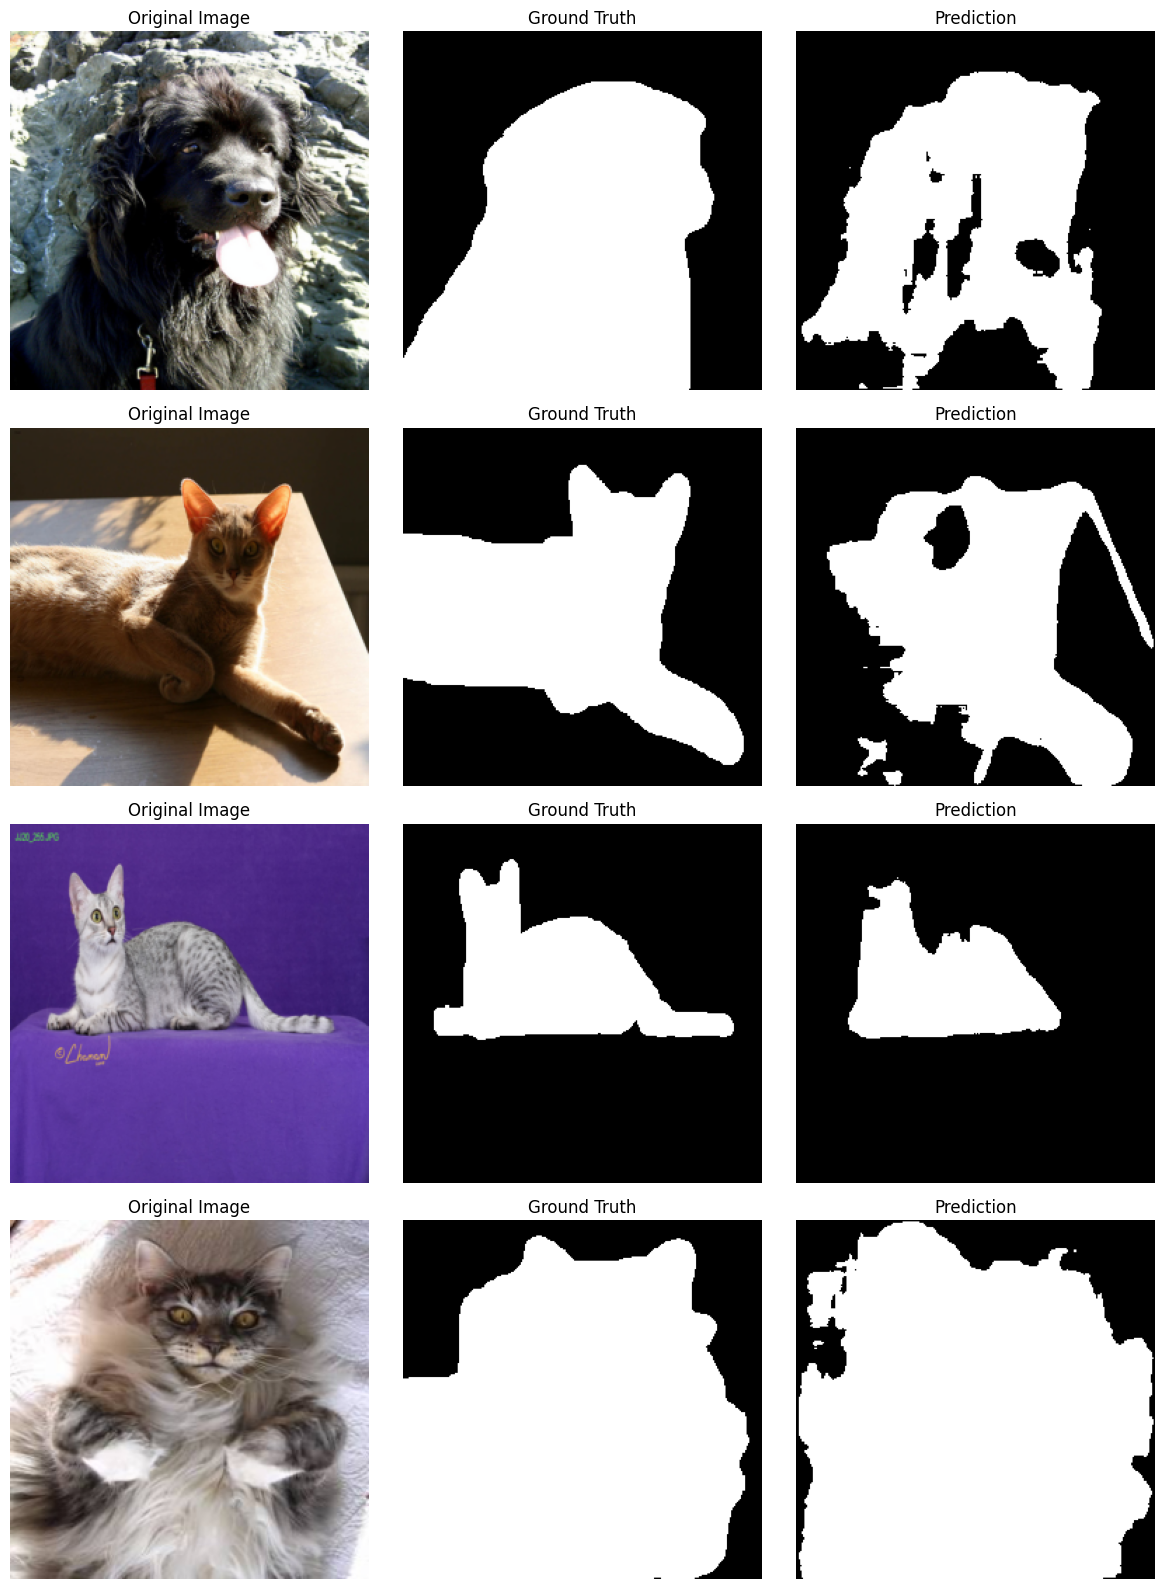

In [ ]:

import torch
import matplotlib.pyplot as plt
import numpy as np

# Load the best trained model
model.load_state_dict(
    torch.load(
        SAVE_DIR / "unet_baseline_best.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

# Get a validation batch
images, masks = next(iter(val_loader))

with torch.no_grad():
    outputs = model(images.to(device))
    probabilities = torch.sigmoid(outputs)
    predictions = (probabilities > 0.5).float()

# Visualize 4 examples
fig, axes = plt.subplots(4, 3, figsize=(12, 16))

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

for i in range(4):

    # Convert normalized image for visualization
    image = images[i].permute(1, 2, 0).numpy()
    image = np.clip(image * std + mean, 0, 1)

    ground_truth = masks[i, 0].numpy()
    prediction = predictions[i, 0].cpu().numpy()

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(
        ground_truth, cmap="gray", vmin=0, vmax=1
    )
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(
        prediction, cmap="gray", vmin=0, vmax=1
    )
    axes[i, 2].set_title("Prediction")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

figure_path = SAVE_DIR / "baseline_predictions.png"

fig.savefig(
    figure_path,
    dpi=150,
    bbox_inches="tight"
)

print("Saved:", figure_path)


Saved: /content/PetVision/baseline_predictions.png


In [ ]:

figure_path = SAVE_DIR / "baseline_predictions.png"

fig.savefig(
    figure_path,
    dpi=150,
    bbox_inches="tight"
)

print("Saved:", figure_path)
print("Exists:", figure_path.exists())


Saved: /content/PetVision/baseline_predictions.png
Exists: True


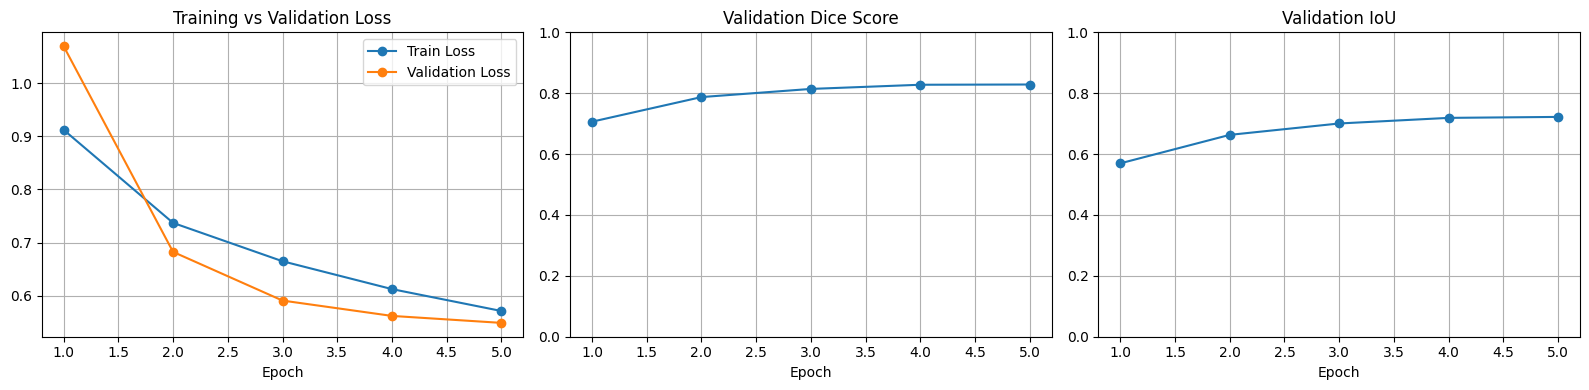

Training curves saved successfully!


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.read_csv(
    SAVE_DIR / "baseline_history.csv"
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Training and Validation Loss
axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train Loss"
)
axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

# Dice Score
axes[1].plot(
    history_df["epoch"],
    history_df["val_dice"],
    marker="o"
)
axes[1].set_title("Validation Dice Score")
axes[1].set_xlabel("Epoch")
axes[1].set_ylim(0, 1)
axes[1].grid(True)

# IoU Score
axes[2].plot(
    history_df["epoch"],
    history_df["val_iou"],
    marker="o"
)
axes[2].set_title("Validation IoU")
axes[2].set_xlabel("Epoch")
axes[2].set_ylim(0, 1)
axes[2].grid(True)

plt.tight_layout()

plt.savefig(
    SAVE_DIR / "baseline_training_curves.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Training curves saved successfully!")


In [ ]:

import random
import numpy as np
import torch

from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

class AugmentedPetDataset(Dataset):

    def __init__(self, subset, augment=False):
        self.subset = subset
        self.augment = augment

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):

        image, mask = self.subset[idx]

        image = TF.resize(
            image,
            (256, 256),
            interpolation=InterpolationMode.BILINEAR
        )

        mask = TF.resize(
            mask,
            (256, 256),
            interpolation=InterpolationMode.NEAREST
        )

        if self.augment:

            # Random horizontal flip
            if random.random() < 0.5:
                image = TF.hflip(image)
                mask = TF.hflip(mask)

            # Random brightness adjustment
            brightness = random.uniform(0.8, 1.2)
            image = TF.adjust_brightness(image, brightness)

            # Random contrast adjustment
            contrast = random.uniform(0.8, 1.2)
            image = TF.adjust_contrast(image, contrast)

        image = TF.to_tensor(image)

        image = TF.normalize(
            image,
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

        mask = np.array(mask)
        mask = (mask != 2).astype(np.float32)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask


print("AugmentedPetDataset created successfully!")


AugmentedPetDataset created successfully!


In [ ]:

BATCH_SIZE = 16

augmented_train_data = AugmentedPetDataset(
    train_subset,
    augment=True
)

augmented_train_loader = DataLoader(
    augmented_train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

print("Augmented training images:", len(augmented_train_data))
print("Training batches:", len(augmented_train_loader))

images, masks = next(iter(augmented_train_loader))

print("Images shape:", images.shape)
print("Masks shape:", masks.shape)
print("Mask values:", torch.unique(masks))

assert images.shape[1:] == (3, 256, 256)
assert masks.shape[1:] == (1, 256, 256)

print("Augmentation pipeline ready!")


Augmented training images: 2944
Training batches: 184
Images shape: torch.Size([16, 3, 256, 256])
Masks shape: torch.Size([16, 1, 256, 256])
Mask values: tensor([0., 1.])
Augmentation pipeline ready!


In [ ]:

import random
import numpy as np
import pandas as pd
import torch
import torch.optim as optim

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Create a new independent model
aug_model = UNet().to(device)

aug_optimizer = optim.AdamW(
    aug_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

EPOCHS = 5
aug_best_dice = -1.0
aug_history = []

print("Starting augmentation experiment...", flush=True)

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        aug_model,
        augmented_train_loader,
        aug_optimizer,
        device
    )

    val_loss, val_dice, val_iou = validate_one_epoch(
        aug_model,
        val_loader,
        device
    )

    aug_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_dice": val_dice,
        "val_iou": val_iou
    })

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Dice: {val_dice:.4f} | "
        f"IoU: {val_iou:.4f}",
        flush=True
    )

    if val_dice > aug_best_dice:
        aug_best_dice = val_dice

        torch.save(
            aug_model.state_dict(),
            SAVE_DIR / "unet_augmented_best.pth"
        )

        print("Best augmented model saved!", flush=True)

    pd.DataFrame(aug_history).to_csv(
        SAVE_DIR / "augmentation_history.csv",
        index=False
    )

print("\nAugmentation experiment completed!")
print(f"Best Augmented Dice: {aug_best_dice:.4f}")
print("Baseline Dice: 0.8286")


Starting augmentation experiment...
Epoch 1/5 | Train Loss: 0.9140 | Val Loss: 0.8963 | Dice: 0.6984 | IoU: 0.5615
Best augmented model saved!
Epoch 2/5 | Train Loss: 0.7491 | Val Loss: 0.7471 | Dice: 0.7653 | IoU: 0.6366
Best augmented model saved!
Epoch 3/5 | Train Loss: 0.6836 | Val Loss: 0.6587 | Dice: 0.7965 | IoU: 0.6769
Best augmented model saved!
Epoch 4/5 | Train Loss: 0.6356 | Val Loss: 0.6056 | Dice: 0.8075 | IoU: 0.6917
Best augmented model saved!
Epoch 5/5 | Train Loss: 0.5902 | Val Loss: 0.7510 | Dice: 0.7895 | IoU: 0.6720

Augmentation experiment completed!
Best Augmented Dice: 0.8075
Baseline Dice: 0.8286


In [ ]:

import shutil
from google.colab import files

archive = shutil.make_archive(
    "/content/PetVision_experiments",
    "zip",
    root_dir="/content",
    base_dir="PetVision"
)

files.download(archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

def train_epoch_with_loss(model, loader, optimizer, device, loss_fn):
    model.train()

    total_loss = 0.0
    total_samples = 0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = loss_fn(outputs, masks)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


@torch.no_grad()
def validate_epoch_with_loss(model, loader, device, loss_fn):
    model.eval()

    total_loss = 0.0
    total_dice = 0.0
    total_iou = 0.0
    total_samples = 0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)
        loss = loss_fn(outputs, masks)

        dice, iou = calculate_metrics(outputs, masks)

        batch_size = images.size(0)

        total_loss += loss.item() * batch_size
        total_dice += dice * batch_size
        total_iou += iou * batch_size
        total_samples += batch_size

    return (
        total_loss / total_samples,
        total_dice / total_samples,
        total_iou / total_samples
    )


print("Flexible training functions ready!")


Flexible training functions ready!


In [ ]:

import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

bce_only_loss = nn.BCEWithLogitsLoss()

bce_model = UNet().to(device)

bce_optimizer = optim.AdamW(
    bce_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

EPOCHS = 5
bce_best_dice = -1.0
bce_history = []

print("Starting BCE-only experiment...", flush=True)

for epoch in range(EPOCHS):

    train_loss = train_epoch_with_loss(
        bce_model, train_loader,
        bce_optimizer, device, bce_only_loss
    )

    val_loss, val_dice, val_iou = validate_epoch_with_loss(
        bce_model, val_loader,
        device, bce_only_loss
    )

    bce_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_dice": val_dice,
        "val_iou": val_iou
    })

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Dice: {val_dice:.4f} | "
        f"IoU: {val_iou:.4f}",
        flush=True
    )

    if val_dice > bce_best_dice:
        bce_best_dice = val_dice

        torch.save(
            bce_model.state_dict(),
            SAVE_DIR / "unet_bce_best.pth"
        )

        print("Best BCE model saved!", flush=True)

    pd.DataFrame(bce_history).to_csv(
        SAVE_DIR / "bce_history.csv",
        index=False
    )

print("\nBCE-only experiment completed!")
print(f"Best BCE Dice: {bce_best_dice:.4f}")


Starting BCE-only experiment...
Epoch 1/5 | Train Loss: 0.5192 | Val Loss: 0.4736 | Dice: 0.7544 | IoU: 0.6217
Best BCE model saved!
Epoch 2/5 | Train Loss: 0.4285 | Val Loss: 0.4252 | Dice: 0.7740 | IoU: 0.6470
Best BCE model saved!
Epoch 3/5 | Train Loss: 0.3944 | Val Loss: 0.4070 | Dice: 0.7233 | IoU: 0.5907
Epoch 4/5 | Train Loss: 0.3640 | Val Loss: 0.3430 | Dice: 0.7953 | IoU: 0.6747
Best BCE model saved!
Epoch 5/5 | Train Loss: 0.3412 | Val Loss: 0.3408 | Dice: 0.8167 | IoU: 0.7048
Best BCE model saved!

BCE-only experiment completed!
Best BCE Dice: 0.8167


In [ ]:

import pandas as pd

experiments = {
    "Baseline": "baseline_history.csv",
    "Augmentation": "augmentation_history.csv",
    "BCE Only": "bce_history.csv"
}

results = []

for name, filename in experiments.items():
    df = pd.read_csv(SAVE_DIR / filename)

    best = df.loc[df["val_dice"].idxmax()]

    results.append({
        "Experiment": name,
        "Best Epoch": int(best["epoch"]),
        "Dice": best["val_dice"],
        "IoU": best["val_iou"],
        "Validation Loss": best["val_loss"]
    })

comparison = pd.DataFrame(results)

comparison = comparison.sort_values(
    "Dice", ascending=False
).reset_index(drop=True)

display(comparison.round(4))

comparison.to_csv(
    SAVE_DIR / "experiment_comparison.csv",
    index=False
)

print("Comparison table saved!")


,Experiment,Best Epoch,Dice,IoU,Validation Loss
0,Baseline,5,0.8286,0.7221,0.5488
1,BCE Only,5,0.8167,0.7048,0.3408
2,Augmentation,4,0.8075,0.6917,0.6056


Comparison table saved!


In [ ]:

files_to_check = [
    "unet_baseline_best.pth",
    "unet_augmented_best.pth",
    "unet_bce_best.pth",
    "baseline_history.csv",
    "augmentation_history.csv",
    "bce_history.csv",
    "experiment_comparison.csv"
]

for filename in files_to_check:
    path = SAVE_DIR / filename
    print(filename, "OK" if path.exists() else "MISSING")


unet_baseline_best.pth OK
unet_augmented_best.pth OK
unet_bce_best.pth OK
baseline_history.csv OK
augmentation_history.csv OK
bce_history.csv OK
experiment_comparison.csv OK


In [ ]:

import shutil
from google.colab import files

archive = shutil.make_archive(
    "/content/PetVision_3_experiments",
    "zip",
    root_dir="/content",
    base_dir="PetVision"
)

files.download(archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import torch

# Load the best baseline model
final_model = UNet().to(device)

final_model.load_state_dict(
    torch.load(
        SAVE_DIR / "unet_baseline_best.pth",
        map_location=device,
        weights_only=True
    )
)

final_model.eval()

print("Best baseline model loaded!")


Best baseline model loaded!


In [ ]:

@torch.no_grad()
def evaluate_test(model, loader, device):
    model.eval()

    total_dice = 0.0
    total_iou = 0.0
    total_samples = 0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        dice, iou = calculate_metrics(
            outputs, masks
        )

        batch_size = images.size(0)

        total_dice += dice * batch_size
        total_iou += iou * batch_size
        total_samples += batch_size

    return (
        total_dice / total_samples,
        total_iou / total_samples
    )


test_dice, test_iou = evaluate_test(
    final_model,
    test_loader,
    device
)

print(f"Test Dice Score: {test_dice:.4f}")
print(f"Test IoU Score: {test_iou:.4f}")


Test Dice Score: 0.8243
Test IoU Score: 0.7194


In [ ]:

import pandas as pd

test_results = pd.DataFrame([{
    "Model": "Baseline U-Net",
    "Test Dice": test_dice,
    "Test IoU": test_iou,
    "Test Samples": len(test_data)
}])

display(test_results.round(4))

test_results.to_csv(
    SAVE_DIR / "final_test_results.csv",
    index=False
)

print("Final test results saved!")


,Model,Test Dice,Test IoU,Test Samples
0,Baseline U-Net,0.8243,0.7194,3669


Final test results saved!


In [ ]:

import torch
import pandas as pd

@torch.no_grad()
def analyze_errors(model, loader, device):
    model.eval()
    results = []
    sample_index = 0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        probabilities = torch.sigmoid(outputs)
        predictions = (probabilities > 0.5).float()

        intersection = (
            predictions * masks
        ).sum(dim=(1, 2, 3))

        pred_sum = predictions.sum(dim=(1, 2, 3))
        target_sum = masks.sum(dim=(1, 2, 3))

        dice = (
            (2 * intersection + 1e-6) /
            (pred_sum + target_sum + 1e-6)
        )

        for score in dice.cpu().tolist():
            results.append({
                "sample_index": sample_index,
                "dice": score
            })
            sample_index += 1

    return pd.DataFrame(results)


error_df = analyze_errors(
    final_model,
    test_loader,
    device
)

print("Total samples:", len(error_df))
print("Average Dice:", round(error_df["dice"].mean(), 4))
print("Median Dice:", round(error_df["dice"].median(), 4))
print("Minimum Dice:", round(error_df["dice"].min(), 4))
print("Maximum Dice:", round(error_df["dice"].max(), 4))

print("\n10 Worst Predictions:")
display(error_df.nsmallest(10, "dice"))

error_df.to_csv(
    SAVE_DIR / "test_error_analysis.csv",
    index=False
)


Total samples: 3669
Average Dice: 0.8243
Median Dice: 0.8636
Minimum Dice: 0.0
Maximum Dice: 0.9837

10 Worst Predictions:


,sample_index,dice
2292,2292,1.875891e-11
1858,1858,1.884481e-11
1093,1093,2.388231e-11
1690,1690,2.388973e-11
2856,2856,3.045531e-11
2837,2837,4.177982e-11
3473,3473,7.559151e-11
2005,2005,3.327139e-02
1136,1136,5.811918e-02
2122,2122,7.019083e-02


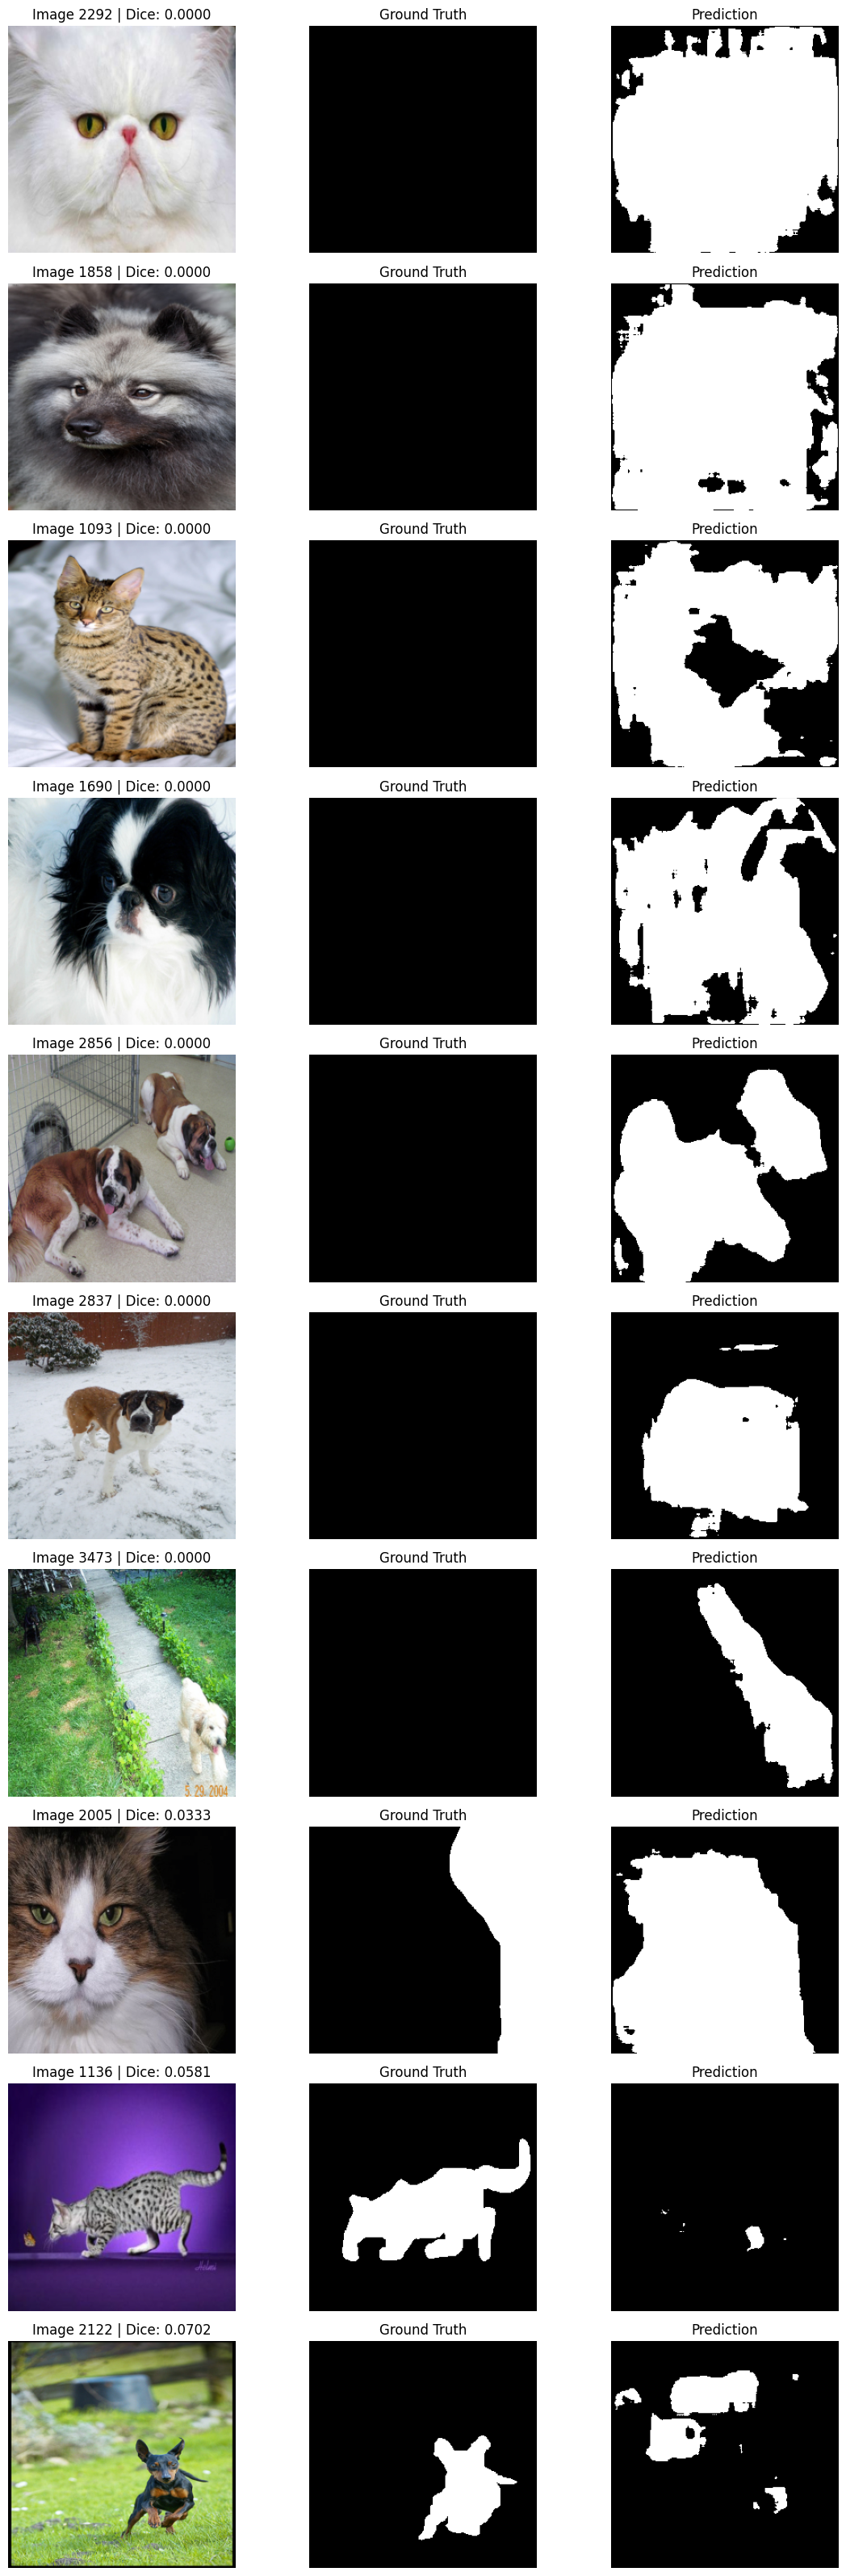

Worst predictions visualization saved!


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import torch

# Select the 10 worst predictions
worst_indices = error_df.nsmallest(
    10, "dice"
)["sample_index"].tolist()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

final_model.eval()

fig, axes = plt.subplots(10, 3, figsize=(12, 32))

with torch.no_grad():

    for row, idx in enumerate(worst_indices):

        image, mask = test_data[idx]

        output = final_model(
            image.unsqueeze(0).to(device)
        )

        probability = torch.sigmoid(output)
        prediction = (probability > 0.5).float()

        # Reverse normalization
        original = image.permute(1, 2, 0).numpy()
        original = np.clip(
            original * std + mean,
            0, 1
        )

        ground_truth = mask[0].numpy()
        predicted_mask = prediction[0, 0].cpu().numpy()

        axes[row, 0].imshow(original)
        axes[row, 0].set_title(
            f"Image {idx} | Dice: "
            f"{error_df.loc[idx, 'dice']:.4f}"
        )

        axes[row, 1].imshow(
            ground_truth, cmap="gray", vmin=0, vmax=1
        )
        axes[row, 1].set_title("Ground Truth")

        axes[row, 2].imshow(
            predicted_mask, cmap="gray", vmin=0, vmax=1
        )
        axes[row, 2].set_title("Prediction")

        for ax in axes[row]:
            ax.axis("off")

plt.tight_layout()

fig.savefig(
    SAVE_DIR / "worst_predictions.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Worst predictions visualization saved!")


In [ ]:

from torchvision.datasets import OxfordIIITPet

test_dataset = OxfordIIITPet(
    root="./data",
    split="test",
    target_types="segmentation",
    download=True
)

print("Test dataset restored!")
print("Test images:", len(test_dataset))


100%|██████████| 792M/792M [00:29<00:00, 27.0MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 8.65MB/s]


Test dataset restored!
Test images: 3669


In [ ]:

print(
    "PetSegmentationDataset:",
    "OK" if "PetSegmentationDataset" in globals()
    else "MISSING"
)

print(
    "test_data:",
    "OK" if "test_data" in globals()
    else "MISSING"
)


PetSegmentationDataset: MISSING
test_data: MISSING


In [ ]:

test_data = PetSegmentationDataset(test_dataset)

print("Test data restored:", len(test_data))


Test data restored: 3669


Image index: 1690
Original mask values: [2]
Processed mask values: [0.]

Original mask pixel distribution:
Value 2: 187500 pixels

Processed foreground pixels: 0


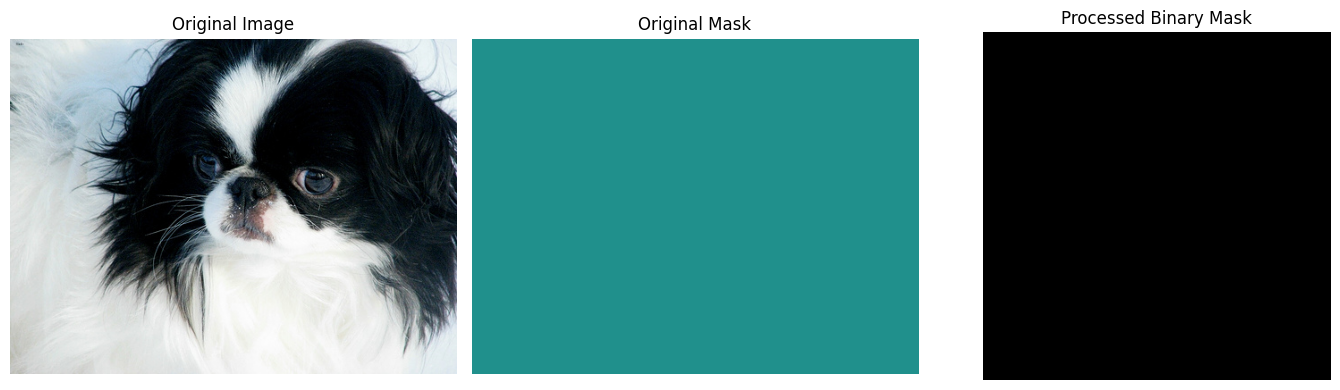

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# One of the worst-performing images
idx = 1690

original_image, original_mask = test_dataset[idx]
processed_image, processed_mask = test_data[idx]

original_array = np.array(original_mask)
processed_array = processed_mask.squeeze().numpy()

print("Image index:", idx)
print("Original mask values:", np.unique(original_array))
print("Processed mask values:", np.unique(processed_array))

values, counts = np.unique(
    original_array,
    return_counts=True
)

print("\nOriginal mask pixel distribution:")
for value, count in zip(values, counts):
    print(f"Value {value}: {count} pixels")

print("\nProcessed foreground pixels:",
      int(processed_array.sum()))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(original_image)
axes[0].set_title("Original Image")

axes[1].imshow(original_array, cmap="viridis", vmin=1, vmax=3)
axes[1].set_title("Original Mask")

axes[2].imshow(processed_array, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Processed Binary Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Image index: 1690
Original mask values: [2]
Processed mask values: [0.]

Original mask pixel distribution:
Value 2: 187500 pixels

Processed foreground pixels: 0


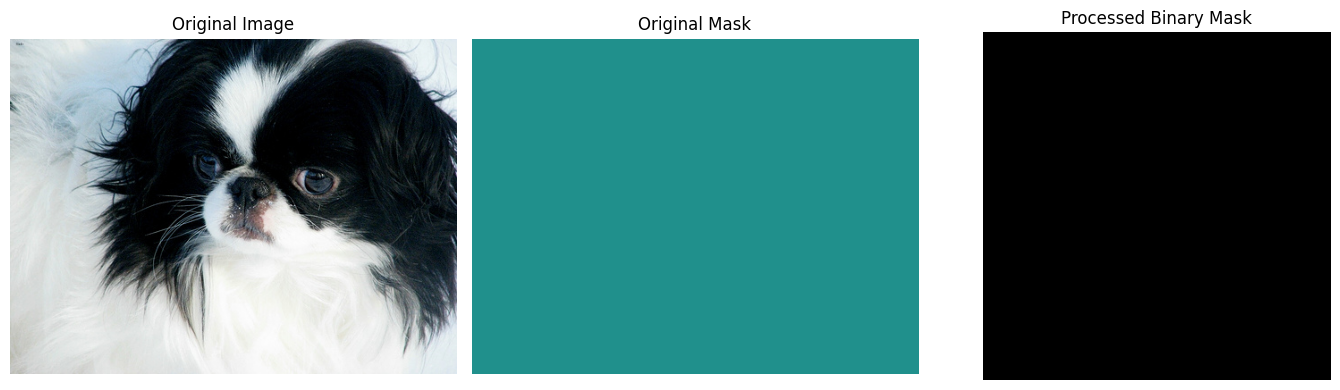

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# One of the worst-performing images
idx = 1690

original_image, original_mask = test_dataset[idx]
processed_image, processed_mask = test_data[idx]

original_array = np.array(original_mask)
processed_array = processed_mask.squeeze().numpy()

print("Image index:", idx)
print("Original mask values:", np.unique(original_array))
print("Processed mask values:", np.unique(processed_array))

values, counts = np.unique(
    original_array,
    return_counts=True
)

print("\nOriginal mask pixel distribution:")
for value, count in zip(values, counts):
    print(f"Value {value}: {count} pixels")

print("\nProcessed foreground pixels:",
      int(processed_array.sum()))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(original_image)
axes[0].set_title("Original Image")

axes[1].imshow(original_array, cmap="viridis", vmin=1, vmax=3)
axes[1].set_title("Original Mask")

axes[2].imshow(processed_array, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Processed Binary Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import numpy as np

empty_masks = []

for idx in range(len(test_dataset)):
    _, mask = test_dataset[idx]

    mask_array = np.array(mask)

    if np.all(mask_array == 2):
        empty_masks.append(idx)

print("Total test images:", len(test_dataset))
print("Empty masks:", len(empty_masks))
print("Indices:", empty_masks)

print(
    "Percentage:",
    round(len(empty_masks) / len(test_dataset) * 100, 2),
    "%"
)


Total test images: 3669
Empty masks: 7
Indices: [1093, 1690, 1858, 2292, 2837, 2856, 3473]
Percentage: 0.19 %


In [ ]:

from pathlib import Path

SAVE_DIR = Path("/content/PetVision")

print("Directory exists:", SAVE_DIR.exists())

if SAVE_DIR.exists():
    print("Saved files:")
    for file in SAVE_DIR.iterdir():
        print("-", file.name)
else:
    print("Folder not found. Previous files need restoration.")


Directory exists: False
Folder not found. Previous files need restoration.


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving PetVision_3_experiments.zip to PetVision_3_experiments.zip


In [ ]:

from pathlib import Path
import zipfile

SAVE_DIR = Path("/content/PetVision")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

zip_path = Path("/content/PetVision_3_experiments.zip")

assert zip_path.exists(), "ZIP file not found!"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Restored files:")

for file in SAVE_DIR.iterdir():
    print("-", file.name)

print("\nRestoration completed!")


Restored files:
- baseline_training_curves.png
- baseline_predictions.png
- bce_history.csv
- augmentation_history.csv
- unet_augmented_best.pth
- unet_bce_best.pth
- experiment_comparison.csv
- unet_baseline_best.pth
- baseline_history.csv

Restoration completed!


In [ ]:

required_objects = [
    "test_dataset",
    "test_data",
    "test_loader",
    "UNet",
    "device",
    "final_model",
    "calculate_metrics"
]

for name in required_objects:
    status = "OK" if name in globals() else "MISSING"
    print(f"{name}: {status}")

print("\nSaved model:")
model_path = SAVE_DIR / "unet_baseline_best.pth"
print("Baseline model:", "OK" if model_path.exists() else "MISSING")


test_dataset: OK
test_data: OK
test_loader: MISSING
UNet: MISSING
device: MISSING
final_model: MISSING
calculate_metrics: MISSING

Saved model:
Baseline model: OK


In [ ]:

import torch
from torch.utils.data import DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

test_loader = DataLoader(
    test_data,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

print("Device:", device)
print("Test batches:", len(test_loader))


Device: cuda
Test batches: 230


In [ ]:

print("DoubleConv:", "DoubleConv" in globals())
print("UNet:", "UNet" in globals())


DoubleConv: True
UNet: True


In [ ]:

from pathlib import Path
import torch

SAVE_DIR = Path("/content/PetVision")

final_model = UNet().to(device)

final_model.load_state_dict(
    torch.load(
        SAVE_DIR / "unet_baseline_best.pth",
        map_location=device,
        weights_only=True
    )
)

final_model.eval()

print("Best baseline model restored!")
print("Device:", device)


Best baseline model restored!
Device: cuda


In [ ]:

required = [
    "test_loader",
    "DoubleConv",
    "UNet",
    "device",
    "final_model",
    "calculate_metrics"
]

for name in required:
    print(
        name,
        "OK" if name in globals() else "MISSING"
    )

assert all(name in globals() for name in required)

print("\nEnvironment restored successfully!")


test_loader OK
DoubleConv OK
UNet OK
device OK
final_model OK
calculate_metrics OK

Environment restored successfully!


In [ ]:

%pip install -q onnx onnxruntime onnxscript


In [ ]:

import torch
import onnx
from pathlib import Path

onnx_path = SAVE_DIR / "unet_baseline.onnx"

# Use CPU for export
export_model = UNet().cpu()

export_model.load_state_dict(
    torch.load(
        SAVE_DIR / "unet_baseline_best.pth",
        map_location="cpu",
        weights_only=True
    )
)

export_model.eval()

dummy_input = torch.randn(
    1, 3, 256, 256,
    device="cpu"
)

torch.onnx.export(
    export_model,
    dummy_input,
    str(onnx_path),
    input_names=["input"],
    output_names=["output"],
    opset_version=18,
    dynamo=True
)

# Validate ONNX model
onnx_model = onnx.load(str(onnx_path))
onnx.checker.check_model(onnx_model)

print("ONNX export successful!")
print("ONNX file:", onnx_path)
print(
    "ONNX size (MB):",
    round(onnx_path.stat().st_size / (1024**2), 2)
)


[torch.onnx] Obtain model graph for `UNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `UNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX export successful!
ONNX file: /content/PetVision/unet_baseline.onnx
ONNX size (MB): 0.06


In [ ]:

import onnxruntime as ort
import numpy as np

session = ort.InferenceSession(
    str(onnx_path),
    providers=["CPUExecutionProvider"]
)

sample_input = np.random.randn(
    1, 3, 256, 256
).astype(np.float32)

onnx_output = session.run(
    ["output"],
    {"input": sample_input}
)[0]

print("ONNX output shape:", onnx_output.shape)

assert onnx_output.shape == (1, 1, 256, 256)

print("ONNX inference test passed!")


ONNX output shape: (1, 1, 256, 256)
ONNX inference test passed!


In [ ]:

import time
import numpy as np
import torch
import onnxruntime as ort

# CPU model
cpu_model = export_model.cpu()
cpu_model.eval()

# Use identical input for both models
sample = torch.randn(1, 3, 256, 256)
sample_numpy = sample.numpy()

# ONNX Runtime
session = ort.InferenceSession(
    str(onnx_path),
    providers=["CPUExecutionProvider"]
)

# Warmup
with torch.inference_mode():
    for _ in range(10):
        cpu_model(sample)

for _ in range(10):
    session.run(["output"], {"input": sample_numpy})

# Benchmark
RUNS = 50

torch_times = []
onnx_times = []

with torch.inference_mode():
    for _ in range(RUNS):
        start = time.perf_counter()
        cpu_model(sample)
        torch_times.append(
            (time.perf_counter() - start) * 1000
        )

for _ in range(RUNS):
    start = time.perf_counter()
    session.run(["output"], {"input": sample_numpy})
    onnx_times.append(
        (time.perf_counter() - start) * 1000
    )

torch_time = np.median(torch_times)
onnx_time = np.median(onnx_times)

speedup = torch_time / onnx_time

print(f"PyTorch median inference: {torch_time:.2f} ms")
print(f"ONNX median inference: {onnx_time:.2f} ms")
print(f"Speedup: {speedup:.2f}x")


PyTorch median inference: 289.76 ms
ONNX median inference: 178.16 ms
Speedup: 1.63x


In [ ]:

# Model file sizes
pytorch_path = SAVE_DIR / "unet_baseline_best.pth"

torch_size = pytorch_path.stat().st_size / (1024**2)
onnx_size = onnx_path.stat().st_size / (1024**2)

# Compare raw output logits
with torch.inference_mode():
    torch_output = cpu_model(sample).numpy()

onnx_output = session.run(
    ["output"],
    {"input": sample_numpy}
)[0]

max_difference = np.max(
    np.abs(torch_output - onnx_output)
)

print(f"PyTorch model size: {torch_size:.2f} MB")
print(f"ONNX model size: {onnx_size:.2f} MB")
print(f"Maximum output difference: {max_difference:.8f}")

print(
    "Outputs close:",
    np.allclose(
        torch_output,
        onnx_output,
        rtol=1e-3,
        atol=1e-4
    )
)


PyTorch model size: 7.40 MB
ONNX model size: 0.06 MB
Maximum output difference: 0.00000238
Outputs close: True


In [ ]:

import pandas as pd

optimization_results = pd.DataFrame([
    {
        "Format": "PyTorch",
        "Size (MB)": torch_size,
        "Median Inference (ms)": torch_time
    },
    {
        "Format": "ONNX Runtime",
        "Size (MB)": onnx_size,
        "Median Inference (ms)": onnx_time
    }
])

display(optimization_results.round(3))

optimization_results.to_csv(
    SAVE_DIR / "optimization_results.csv",
    index=False
)

print("Optimization results saved!")


,Format,Size (MB),Median Inference (ms)
0,PyTorch,7.402,289.756
1,ONNX Runtime,0.061,178.163


Optimization results saved!


In [ ]:

from pathlib import Path

for file in SAVE_DIR.iterdir():
    if file.suffix == ".onnx" or "onnx" in file.name.lower() or file.name.endswith(".data"):
        print(
            file.name,
            round(file.stat().st_size / (1024 ** 2), 3),
            "MB"
        )


unet_baseline.onnx.data 7.344 MB
unet_baseline.onnx 0.061 MB


In [ ]:

import torch
import numpy as np
import onnxruntime as ort

# Exactly the same input for both models
sample = torch.randn(1, 3, 256, 256)

# PyTorch prediction
cpu_model = final_model.cpu().eval()

with torch.inference_mode():
    pytorch_output = cpu_model(sample).numpy()

# ONNX prediction
session = ort.InferenceSession(
    str(SAVE_DIR / "unet_baseline.onnx"),
    providers=["CPUExecutionProvider"]
)

onnx_output = session.run(
    ["output"],
    {"input": sample.numpy()}
)[0]

# Compare logits
max_diff = np.max(
    np.abs(pytorch_output - onnx_output)
)

outputs_close = np.allclose(
    pytorch_output,
    onnx_output,
    rtol=1e-3,
    atol=1e-4
)

print("Maximum difference:", max_diff)
print("Outputs close:", outputs_close)

assert outputs_close, "ONNX and PyTorch outputs differ!"


Maximum difference: 2.3841858e-06
Outputs close: True


In [ ]:
### Application part


In [ ]:

%%writefile /content/PetVision/app.py
from pathlib import Path
from io import BytesIO

import numpy as np
import onnxruntime as ort
import streamlit as st
from PIL import Image, ImageOps

MODEL_PATH = Path(__file__).parent / "unet_baseline.onnx"

IMAGE_SIZE = 256
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


@st.cache_resource
def load_model():
    if not MODEL_PATH.exists():
        raise FileNotFoundError(
            f"Model file not found: {MODEL_PATH}"
        )

    return ort.InferenceSession(
        str(MODEL_PATH),
        providers=["CPUExecutionProvider"]
    )


def preprocess_image(image):
    image = image.convert("RGB")
    resized = image.resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.BILINEAR
    )

    array = np.asarray(resized, dtype=np.float32) / 255.0
    array = (array - MEAN) / STD

    # HWC -> CHW -> NCHW
    array = np.transpose(array, (2, 0, 1))
    array = np.expand_dims(array, axis=0)

    return np.ascontiguousarray(array, dtype=np.float32)


def predict_mask(image, session, threshold):
    input_array = preprocess_image(image)

    logits = session.run(
        ["output"],
        {"input": input_array}
    )[0]

    # Convert logits to probabilities
    probabilities = 1.0 / (
        1.0 + np.exp(-np.clip(logits, -50, 50))
    )

    mask = (probabilities[0, 0] > threshold).astype(np.uint8)
    mask_image = Image.fromarray(mask * 255, mode="L")

    # Restore original image size
    mask_image = mask_image.resize(
        image.size,
        Image.Resampling.NEAREST
    )

    return mask_image


def create_overlay(image, mask):
    original = image.convert("RGB")
    original_array = np.asarray(original, dtype=np.float32)
    mask_array = np.asarray(mask) > 0

    overlay_array = original_array.copy()
    red = np.array([255, 60, 80], dtype=np.float32)

    overlay_array[mask_array] = (
        0.55 * original_array[mask_array]
        + 0.45 * red
    )

    return Image.fromarray(
        np.clip(overlay_array, 0, 255).astype(np.uint8)
    )


def create_transparent_image(image, mask):
    result = image.convert("RGBA")
    result.putalpha(mask)
    return result


def image_to_png_bytes(image):
    buffer = BytesIO()
    image.save(buffer, format="PNG")
    return buffer.getvalue()


st.set_page_config(
    page_title="PetVision Studio",
    page_icon="🐾",
    layout="wide"
)

st.title("PetVision Studio")
st.write(
    "AI-powered pet segmentation using a custom U-Net model."
)

st.caption(
    "Upload a cat or dog image to separate the pet "
    "from its background."
)

threshold = st.sidebar.slider(
    "Segmentation threshold",
    min_value=0.1,
    max_value=0.9,
    value=0.5,
    step=0.05
)

uploaded_file = st.file_uploader(
    "Upload an image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:
    try:
        image = Image.open(uploaded_file)
        image = ImageOps.exif_transpose(image).convert("RGB")

        session = load_model()

        with st.spinner("Segmenting pet..."):
            mask = predict_mask(image, session, threshold)
            overlay = create_overlay(image, mask)
            transparent = create_transparent_image(image, mask)

        st.success("Segmentation complete!")

        col1, col2, col3 = st.columns(3)

        with col1:
            st.subheader("Original")
            st.image(image, use_container_width=True)

        with col2:
            st.subheader("Predicted Mask")
            st.image(mask, use_container_width=True)

        with col3:
            st.subheader("Overlay")
            st.image(overlay, use_container_width=True)

        st.subheader("Transparent Background")

        st.image(
            transparent,
            use_container_width=True
        )

        st.download_button(
            label="Download transparent PNG",
            data=image_to_png_bytes(transparent),
            file_name="petvision_segmentation.png",
            mime="image/png"
        )

    except Exception as error:
        st.error(f"Could not process image: {error}")

st.divider()

st.caption(
    "Model: Custom U-Net | "
    "Dataset: Oxford-IIIT Pet | "
    "Inference: ONNX Runtime"
)


Writing /content/PetVision/app.py


In [ ]:

%%writefile /content/PetVision/requirements.txt
streamlit>=1.35,<2
onnxruntime>=1.18,<2
numpy>=1.26,<3
Pillow>=10,<13


Writing /content/PetVision/requirements.txt


In [ ]:

import ast
from pathlib import Path
import numpy as np
import onnxruntime as ort

app_path = SAVE_DIR / "app.py"
requirements_path = SAVE_DIR / "requirements.txt"
onnx_path = SAVE_DIR / "unet_baseline.onnx"
onnx_data_path = SAVE_DIR / "unet_baseline.onnx.data"

# Check required files
for path in [
    app_path,
    requirements_path,
    onnx_path,
    onnx_data_path
]:
    assert path.exists(), f"Missing: {path.name}"
    print("OK:", path.name)

# Check Python syntax
source = app_path.read_text(encoding="utf-8")
ast.parse(source)
print("Python syntax: OK")

# Check ONNX model inference
session = ort.InferenceSession(
    str(onnx_path),
    providers=["CPUExecutionProvider"]
)

test_input = np.zeros(
    (1, 3, 256, 256),
    dtype=np.float32
)

test_output = session.run(
    ["output"],
    {"input": test_input}
)[0]

assert test_output.shape == (1, 1, 256, 256)
assert np.isfinite(test_output).all()

print("ONNX inference: OK")
print("Core file checks passed!")


OK: app.py
OK: requirements.txt
OK: unet_baseline.onnx
OK: unet_baseline.onnx.data
Python syntax: OK
ONNX inference: OK
Core file checks passed!


In [ ]:

%pip install -q "streamlit>=1.35,<2"


In [ ]:

import subprocess
import time

process = subprocess.Popen(
    [
        "streamlit", "run",
        str(SAVE_DIR / "app.py"),
        "--server.headless=true",
        "--server.port=8501",
        "--server.address=127.0.0.1"
    ],
    stdout=open("/content/streamlit.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit process running:", process.poll() is None)

print(
    Path("/content/streamlit.log")
    .read_text(encoding="utf-8")[-1500:]
)


Streamlit process running: True


2026-10-25 11:20:31.791 Uvicorn server started on 127.0.0.1:8501

  You can now view your Streamlit app in your browser.

  URL: http://127.0.0.1:8501




In [ ]:

import zipfile
from pathlib import Path
from google.colab import files

zip_path = Path("/content/PetVision_Studio_App.zip")

app_files = [
    "app.py",
    "requirements.txt",
    "unet_baseline.onnx",
    "unet_baseline.onnx.data"
]

with zipfile.ZipFile(
    zip_path, "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:
    for filename in app_files:
        source = SAVE_DIR / filename
        assert source.exists(), f"Missing: {filename}"

        archive.write(
            source,
            arcname=f"PetVision_Studio/{filename}"
        )

print("Deployment ZIP created:", zip_path)
print(
    "ZIP size:",
    round(zip_path.stat().st_size / (1024**2), 2),
    "MB"
)

files.download(str(zip_path))


Deployment ZIP created: /content/PetVision_Studio_App.zip
ZIP size: 6.83 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#ტესტირება სეგმენტაციის სისუსტის გამო

In [ ]:

import numpy as np
import torch
import onnxruntime as ort

final_model = final_model.cpu().eval()

# Same input for both models
test_input = torch.randn(1, 3, 256, 256)

with torch.inference_mode():
    torch_logits = final_model(test_input).numpy()

session = ort.InferenceSession(
    str(SAVE_DIR / "unet_baseline.onnx"),
    providers=["CPUExecutionProvider"]
)

onnx_logits = session.run(
    ["output"],
    {"input": test_input.numpy()}
)[0]

print(
    "Maximum difference:",
    np.max(np.abs(torch_logits - onnx_logits))
)

print(
    "Outputs close:",
    np.allclose(
        torch_logits,
        onnx_logits,
        rtol=1e-3,
        atol=1e-4
    )
)

print("PyTorch output range:", torch_logits.min(), torch_logits.max())
print("ONNX output range:", onnx_logits.min(), onnx_logits.max())


Maximum difference: 2.3841858e-06
Outputs close: True
PyTorch output range: -6.6165724 -1.8809865
ONNX output range: -6.6165724 -1.8809865


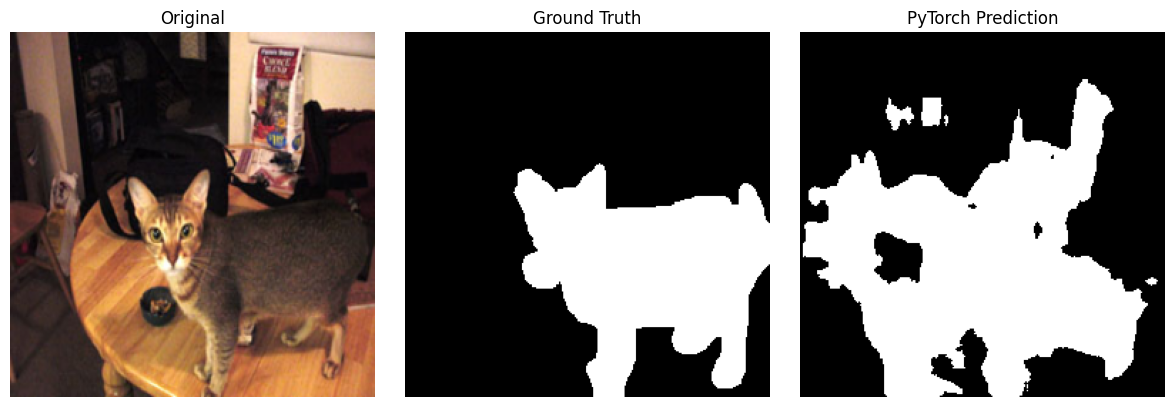

Probability min: 0.0015719922
Probability max: 0.99634296
Predicted foreground %: 42.52


In [ ]:

import torch
import numpy as np
import matplotlib.pyplot as plt

final_model = final_model.cpu().eval()

# Take one actual image from our test dataset
image_tensor, true_mask = test_data[0]

with torch.inference_mode():
    logits = final_model(
        image_tensor.unsqueeze(0)
    )

probabilities = torch.sigmoid(logits)[0, 0].numpy()
prediction = (probabilities > 0.5).astype(np.uint8)

# Convert normalized image back for display
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image = image_tensor.permute(1, 2, 0).numpy()
image = np.clip(image * std + mean, 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image)
axes[0].set_title("Original")

axes[1].imshow(true_mask.squeeze().numpy(), cmap="gray")
axes[1].set_title("Ground Truth")

axes[2].imshow(prediction, cmap="gray")
axes[2].set_title("PyTorch Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Probability min:", probabilities.min())
print("Probability max:", probabilities.max())
print("Predicted foreground %:", round(prediction.mean() * 100, 2))


In [ ]:

# Compare prediction with ground truth

pred = torch.tensor(prediction, dtype=torch.float32)
target = true_mask.squeeze().cpu().float()

intersection = (pred * target).sum()
dice = (2 * intersection + 1e-6) / (
    pred.sum() + target.sum() + 1e-6
)

print("Sample Dice:", round(dice.item(), 4))
print("Ground truth foreground %:",
      round(target.mean().item() * 100, 2))
print("Predicted foreground %:",
      round(pred.mean().item() * 100, 2))


Sample Dice: 0.5807
Ground truth foreground %: 26.52
Predicted foreground %: 42.52


In [ ]:

import torch
import numpy as np

final_model = final_model.cpu().eval()

all_dice = []

with torch.inference_mode():
    for images, masks in test_loader:
        images = images.cpu()
        masks = masks.cpu()

        logits = final_model(images)
        predictions = (torch.sigmoid(logits) > 0.5).float()

        p = predictions.flatten(start_dim=1)
        t = masks.flatten(start_dim=1)

        intersection = (p * t).sum(dim=1)
        dice = (2 * intersection + 1e-6) / (
            p.sum(dim=1) + t.sum(dim=1) + 1e-6
        )

        all_dice.extend(dice.numpy().tolist())

print("Evaluated images:", len(all_dice))
print("Average Test Dice:", round(np.mean(all_dice), 4))
print("Median Test Dice:", round(np.median(all_dice), 4))
print("Images with Dice below 0.5:", sum(d < 0.5 for d in all_dice))
print("Images with Dice above 0.8:", sum(d > 0.8 for d in all_dice))


Evaluated images: 3669
Average Test Dice: 0.8243
Median Test Dice: 0.8636
Images with Dice below 0.5: 122
Images with Dice above 0.8: 2588


In [ ]:

import numpy as np
import torch
from PIL import Image
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

# Take exactly the same original test image
original_image, _ = test_dataset[0]
original_image = original_image.convert("RGB")

# Method A: Training preprocessing
training_resized = TF.resize(
    original_image,
    [256, 256],
    interpolation=InterpolationMode.BILINEAR
)

training_tensor = TF.to_tensor(training_resized)

training_tensor = TF.normalize(
    training_tensor,
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

# Method B: Streamlit preprocessing
app_resized = original_image.resize(
    (256, 256),
    Image.Resampling.BILINEAR
)

mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

app_array = np.asarray(
    app_resized, dtype=np.float32
) / 255.0

app_array = (app_array - mean) / std
app_array = np.transpose(app_array, (2, 0, 1))

# Compare preprocessed inputs
training_array = training_tensor.numpy()

difference = np.abs(training_array - app_array)

print("Maximum input difference:", difference.max())
print("Mean input difference:", difference.mean())

print(
    "Inputs close:",
    np.allclose(
        training_array,
        app_array,
        atol=1e-5
    )
)


Maximum input difference: 0.0
Mean input difference: 0.0
Inputs close: True


In [ ]:

import numpy as np
import onnxruntime as ort

session = ort.InferenceSession(
    str(SAVE_DIR / "unet_baseline.onnx"),
    providers=["CPUExecutionProvider"]
)

# Training preprocessing
input_a = training_array[np.newaxis].astype(np.float32)

# Streamlit preprocessing
input_b = app_array[np.newaxis].astype(np.float32)

logits_a = session.run(
    ["output"], {"input": input_a}
)[0]

logits_b = session.run(
    ["output"], {"input": input_b}
)[0]

mask_a = (logits_a > 0).astype(np.uint8)
mask_b = (logits_b > 0).astype(np.uint8)

print(
    "Maximum logit difference:",
    np.max(np.abs(logits_a - logits_b))
)

print(
    "Different mask pixels:",
    int(np.sum(mask_a != mask_b))
)

print(
    "Mask agreement (%):",
    round(np.mean(mask_a == mask_b) * 100, 3)
)


Maximum logit difference: 0.0
Different mask pixels: 0
Mask agreement (%): 100.0
